In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import build_model, halofit

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

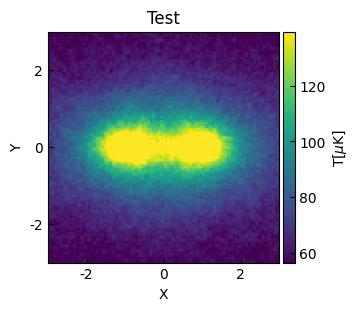

In [3]:
coord = get_coord()

data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
plot_heatmap(data, title='Test')

In [4]:
name = 'lorentz'
bg_name = 'poly'

tolenrance = 0.1

bounds = {
    'amplitude_0': (0, None),
    'amplitude_1': (0, None),
    'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    'y_mean_1': (0 - tolenrance, 0 + tolenrance),
}

constraints = {
    # "fixed": ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'], # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0")  # amplitude_1 = amplitude_0
    ]
}

model = build_model(name, bg_name, bounds=bounds, constraints=constraints)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=50., x_mean=-1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [1]: <Lorentz2D(amplitude=50., x_mean=1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [2]: <Polynomial2D(2, c0_0=0., c1_0=0., c2_0=0., c0_1=0., c0_2=0., c1_1=0., x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 fwhm_0 ... c2_0_2 c0_1_2 c0_2_2 c1_1_2
    ----------- -------- -------- ------ ... ------ ------ ------ ------
           50.0     -1.0      0.0    1.0 ...    0.0    0.0    0.0    0.0


# without mask

In [5]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=2197.57715517, x_mean=-1.01892463, y_mean=-0.00010575, fwhm=0.1, ellipticity=0.21538479, theta=-84.8401565)>

    [1]: <Lorentz2D(amplitude=2197.57715517, x_mean=1.01891053, y_mean=-0.00003888, fwhm=0.1, ellipticity=0.22006139, theta=-50.27922652)>

    [2]: <Polynomial2D(2, c0_0=96.25128785, c1_0=0.1467166, c2_0=-21.22522243, c0_1=-0.28060784, c0_2=-44.3169741, c1_1=-0.58012018, x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
       amplitude_0          x_mean_0      ...       c0_2_2              c1_1_2      
    ----------------- ------------------- ... ------------------ -------------------
    2197.577155167274 -1.0189246271521364 ... -44.31697409556758 -0.5801201792377846

Goodness of fit:
Chi-squared: 3008451.320
RMS residual: 14.454


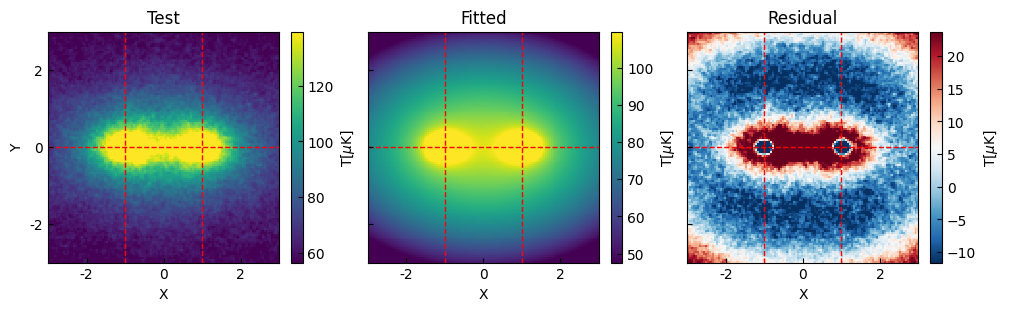

In [6]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

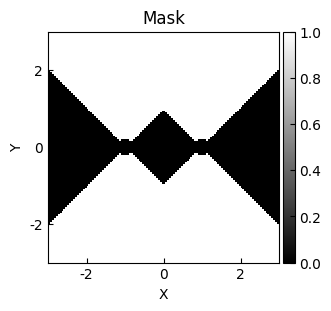

In [7]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [8]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=121.54350729, x_mean=-0.92965898, y_mean=0.00620864, fwhm=1.35164487, ellipticity=0.25117367, theta=59.66106821)>

    [1]: <Lorentz2D(amplitude=121.54350729, x_mean=0.92584306, y_mean=0.00098431, fwhm=1.3362077, ellipticity=0.24873113, theta=78.51842711)>

    [2]: <Polynomial2D(2, c0_0=56.80010917, c1_0=0.20762148, c2_0=-1.43643717, c0_1=-0.32212818, c0_2=-5.76409413, c1_1=-0.37067402, x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
       amplitude_0           x_mean_0      ...        c1_1_2      
    ------------------ ------------------- ... -------------------
    121.54350729019154 -0.9296589788859255 ... -0.3706740200257419

Goodness of fit:
Chi-squared: 17030246.999
RMS residual: 34.390


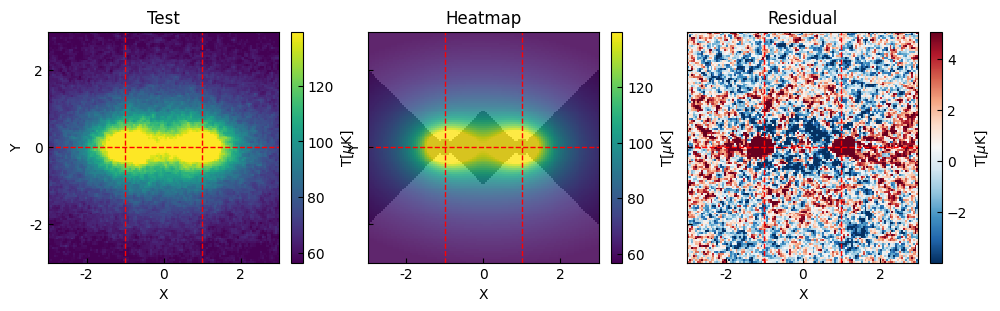

In [9]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

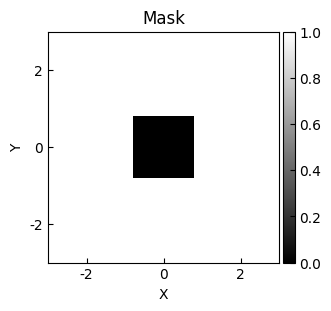

In [10]:
mask = ~get_mask_square(coord=coord, xlim=[-0.8, 0.8], ylim=[-0.8, 0.8])
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [11]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=2147.01617485, x_mean=-1.01872831, y_mean=-0.00005556, fwhm=0.1, ellipticity=0.199292, theta=-102.10016757)>

    [1]: <Lorentz2D(amplitude=2147.01617485, x_mean=1.01927905, y_mean=-0.00000904, fwhm=0.1, ellipticity=0.18576654, theta=-25.20098798)>

    [2]: <Polynomial2D(2, c0_0=88.71875898, c1_0=0.23116918, c2_0=-13.17426271, c0_1=-0.2847649, c0_2=-36.87135587, c1_1=-0.56151803, x_domain=(-3, 3), y_domain=(-3, 3))>
Parameters:
       amplitude_0         x_mean_0      ...       c0_2_2             c1_1_2      
    ----------------- ------------------ ... ----------------- -------------------
    2147.016174853608 -1.018728313297859 ... -36.8713558746039 -0.5615180326856308

Goodness of fit:
Chi-squared: 3331489.956
RMS residual: 15.210


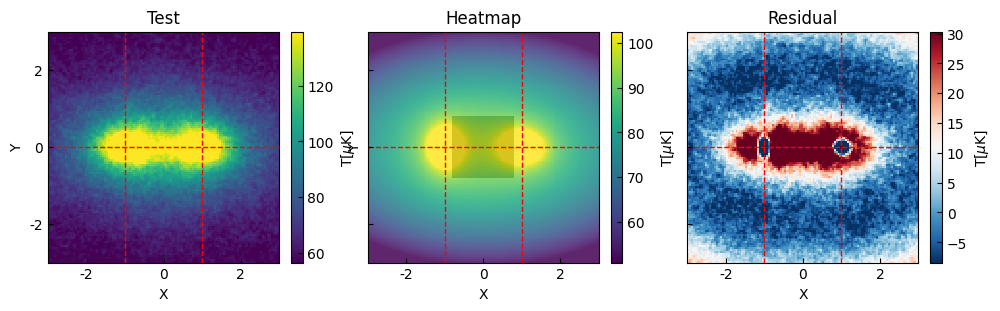

In [12]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [13]:
from mytools.plot import plot_hist

(-100.0, 100.0)

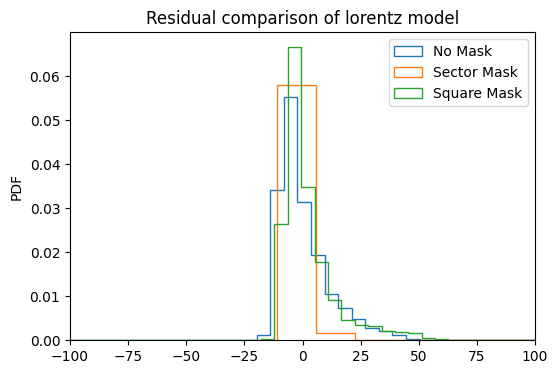

In [14]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model' %(name)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

In [15]:
from mytools.plot import plot_line,plt

In [16]:
stack_fit_res = data_list_sector

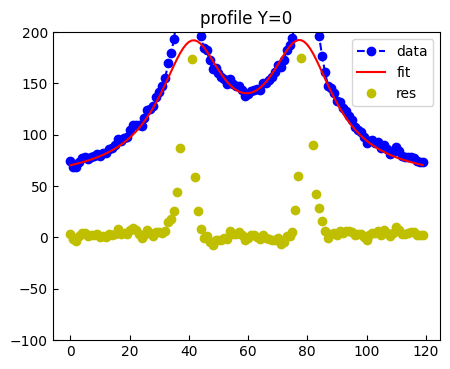

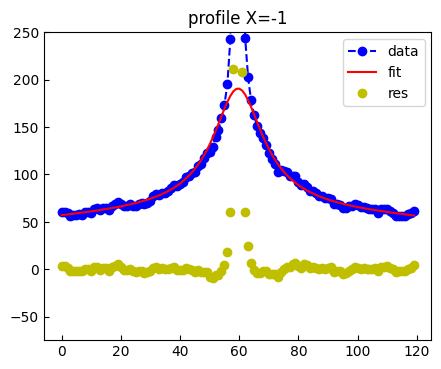

In [17]:
xx = [range(120)]*3

ind = 60
yy = [d[ind] for d in stack_fit_res]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.ylim(ymax=200)
plt.legend()

ind = 40
yy = [d[:, ind] for d in stack_fit_res]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.ylim(ymax=250)
plt.legend()

# estimate signal level

In [18]:
from mytools.estimate import get_signal_level
from mytools.plot import plot_profile_2c, plot_hist, make_figure

Gauss fit parameters a, sgima, c (and mu): [-3.06701793  0.5         0.61311272]
Gauss fit covariance of a, sgima, c (and mu): [[ 0.15271612  0.01127855 -0.01730346]
 [ 0.01127855  0.00627882  0.00564178]
 [-0.01730346  0.00564178  0.02447078]]
width: 0.49999999999999956
width_pix: 10


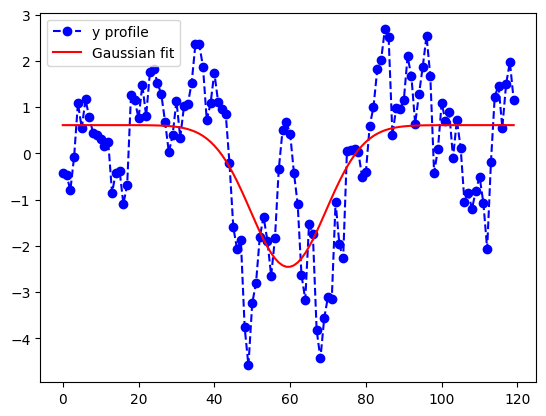

In [19]:
res = stack_fit_res[-1]
# bounds = (
#     [0, 0, -np.inf],
#     [np.inf, 0.5, np.inf],
# )
lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

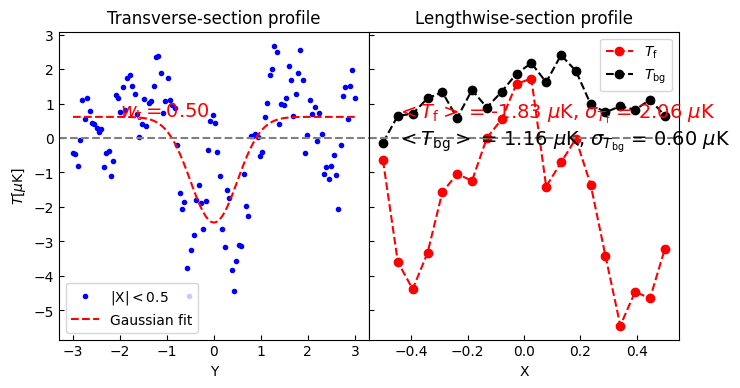

In [20]:
fig, axes = make_figure(1, 2, figsize=(8,4),wspace=0.,aspect=None,sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[1])

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

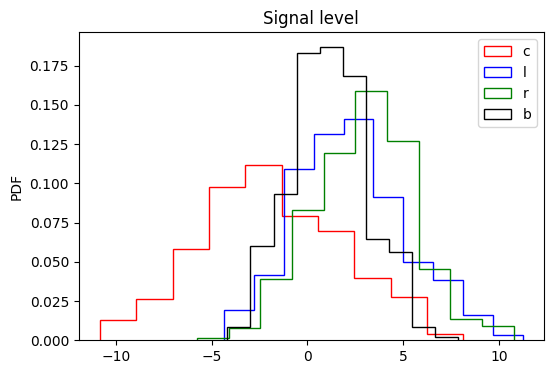

In [21]:
plot_hist(clrb, label=['c','l','r','b'], color=['r', 'b','g','k'], title='Signal level')